<a href="https://colab.research.google.com/github/keshav581/UCS420/blob/main/KeshavSingh_A7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
ROLL_NO = 1024170166
NAME = "Keshav Singh"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)


In [23]:
import random, hashlib
import pandas as pd
from nltk.tokenize import RegexpTokenizer
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

In [13]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [14]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170166   Name: Keshav Singh   Fingerprint: 42BF8BDD   Tickets: 13

Ticket_ID                                                                                       Ticket_Text
      T01                I reinstalled the WiFi after restarting the system. The same problem occurs again.
      T02                                                              Python 3.12 was installed yesterday.
      T03                                     Email has stopped syncing during the lab. Can you check this?
      T04                                            The server is not working. I have tried several times!
      T05                   Email failed to open when connected to campus Wi-Fi. Is there another solution?
      T06 I keep getting logged out of the wifi after restarting the system. The same problem occurs again.
      T07                            Student portal crashes while opening on my laptop. Can you check this?
      T08                                           

In [15]:
#Q1

# Q1. Preprocessing Pipeline

rows = []

total_sentences = 0
total_tokens = 0
total_punct = 0
total_stop = 0
total_unique = 0
total_final = 0

for _, row in df.iterrows():

    result = process_ticket(row["Ticket_Text"])

    sentences = result["sentences"]
    tokens = result["tokens"]
    punct = result["punct"]
    stops = result["stops"]
    final = result["final"]
    unique = sorted(set(tokens))

    rows.append({
    "Ticket_ID": row["Ticket_ID"],
    "Ticket_Text": row["Ticket_Text"],
    "Sentences": len(sentences),
    "Tokens": len(tokens),
    "Punctuation": len(punct),
    "Stopwords": len(stops),
    "Unique Tokens": len(unique),
    "Final Tokens": len(final)
})

    total_sentences += len(sentences)
    total_tokens += len(tokens)
    total_punct += len(punct)
    total_stop += len(stops)
    total_unique += len(unique)
    total_final += len(final)

result_df = pd.DataFrame(rows)

# TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Ticket_Text": "",
    "Sentences": total_sentences,
    "Tokens": total_tokens,
    "Punctuation": total_punct,
    "Stopwords": total_stop,
    "Unique Tokens": total_unique,
    "Final Tokens": total_final
}

result_df.loc[len(result_df)] = total_row

display(result_df)

selected_ticket = df.iloc[0]

result = process_ticket(selected_ticket["Ticket_Text"])

print("Ticket ID:", selected_ticket["Ticket_ID"])
print("Ticket Text:", selected_ticket["Ticket_Text"])

print("\nTokens:")
print(result["tokens"])

print("\nPunctuation Tokens:")
print(result["punct"])

print("\nStopwords:")
print(result["stops"])

print("\nFinal Tokens:")
print(result["final"])

,Ticket_ID,Ticket_Text,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,I reinstalled the WiFi after restarting the sy...,2,15,2,7,12,6
1,T02,Python 3.12 was installed yesterday.,1,6,1,1,6,4
2,T03,Email has stopped syncing during the lab. Can ...,2,13,2,6,13,5
3,T04,The server is not working. I have tried severa...,2,12,2,5,12,5
4,T05,Email failed to open when connected to campus ...,2,15,2,5,14,8
5,T06,I keep getting logged out of the wifi after re...,2,19,2,9,16,8
6,T07,Student portal crashes while opening on my lap...,2,14,2,6,14,6
7,T08,See https://lms.thapar.edu/help for details.,1,7,2,1,7,4
8,T09,I can't login and I didn't change anything.,1,11,1,4,9,6
9,T10,I am unable to use the MATLAB after the latest...,2,16,2,7,14,7


Ticket ID: T01
Ticket Text: I reinstalled the WiFi after restarting the system. The same problem occurs again.

Tokens:
['i', 'reinstalled', 'the', 'wifi', 'after', 'restarting', 'the', 'system', '.', 'the', 'same', 'problem', 'occurs', 'again', '.']

Punctuation Tokens:
['.', '.']

Stopwords:
['i', 'the', 'after', 'the', 'the', 'same', 'again']

Final Tokens:
['reinstalled', 'wifi', 'restarting', 'system', 'problem', 'occurs']


In [19]:
#Q2

#Using the raw tickets and Python re:

import re

for _, row in df.iterrows():

    text = row["Ticket_Text"]

    long_words = re.findall(r"\b[a-zA-Z]{6,}\b", text)

    numbers = re.findall(r"\b\d+(?:\.\d+)*\b", text)

    capitalized = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)

    vowel_words = re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", text)

    replaced = re.sub(r"[\w\.-]+@[\w\.-]+\.\w+", "<EMAIL>", text)
    replaced = re.sub(r"(https?://\S+|www\.\S+)", "<URL>", replaced)
    replaced = re.sub(r"(?:\+91[- ]?)?\d{5}[- ]?\d{5}|\d{4}-\d{3}-\d{4}", "<PHONE>", replaced)

    print("="*60)
    print("Ticket:", row["Ticket_ID"])
    print("Original:", text)
    print("Words >5:", long_words)
    print("Numbers:", numbers)
    print("Capitalized:", capitalized)
    print("Starts with vowel:", vowel_words)
    print("After Replacement:", replaced)

#Testing whether it works on TEST_LINES:

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu for support.",
    "See https://lms.thapar.edu/help for details.",
    "Call me on +91 98765 43210 or 0175-239-3201.",
    "Version 2.0.1 crashes at 99%."
]

for line in TEST_LINES:
    print("\nOriginal:", line)

    print("Words >5:", re.findall(r"\b[a-zA-Z]{6,}\b", line))
    print("Numbers:", re.findall(r"\b\d+(?:\.\d+)*\b", line))
    print("Capitalized:", re.findall(r"\b[A-Z][a-zA-Z]*\b", line))
    print("Starts with vowel:", re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", line))

    replaced = re.sub(r"[\w\.-]+@[\w\.-]+\.\w+", "<EMAIL>", line)
    replaced = re.sub(r"(https?://\S+|www\.\S+)", "<URL>", replaced)
    replaced = re.sub(r"(?:\+91[- ]?)?\d{5}[- ]?\d{5}|\d{4}-\d{3}-\d{4}", "<PHONE>", replaced)

    print("After Replacement:", replaced)

Ticket: T01
Original: I reinstalled the WiFi after restarting the system. The same problem occurs again.
Words >5: ['reinstalled', 'restarting', 'system', 'problem', 'occurs']
Numbers: []
Capitalized: ['I', 'WiFi', 'The']
Starts with vowel: ['I', 'after', 'occurs', 'again']
After Replacement: I reinstalled the WiFi after restarting the system. The same problem occurs again.
Ticket: T02
Original: Python 3.12 was installed yesterday.
Words >5: ['Python', 'installed', 'yesterday']
Numbers: ['3.12']
Capitalized: ['Python']
Starts with vowel: ['installed']
After Replacement: Python 3.12 was installed yesterday.
Ticket: T03
Original: Email has stopped syncing during the lab. Can you check this?
Words >5: ['stopped', 'syncing', 'during']
Numbers: []
Capitalized: ['Email', 'Can']
Starts with vowel: ['Email']
After Replacement: Email has stopped syncing during the lab. Can you check this?
Ticket: T04
Original: The server is not working. I have tried several times!
Words >5: ['server', 'working'

In [22]:
#Q3

#Creating tokenizer pattern
pattern = r"""
(?:https?://\S+|www\.\S+)                 # URLs
|(?:[\w\.-]+@[\w\.-]+\.\w+)               # Emails
|(?:\+?\d[\d -]*\d)                       # Phone numbers
|(?:\d+\.\d+(?:\.\d+)*)                   # Decimals and versions
|(?:[A-Za-z]+(?:-[A-Za-z]+)+)             # Hyphenated words
|(?:[A-Za-z]+(?:'[A-Za-z]+)?)             # Words with contractions
|(?:\d+)                                  # Normal numbers
"""

tokenizer = RegexpTokenizer(pattern, flags=re.VERBOSE)

def my_tokenize(text):
    return tokenizer.tokenize(text)

#Running on tickets

for _, row in df.iterrows():
    print("="*50)
    print("Ticket:", row["Ticket_ID"])

    print("Custom Tokenizer:")
    print(my_tokenize(row["Ticket_Text"]))

    print("word_tokenize:")
    print(word_tokenize(row["Ticket_Text"]))

#Running on TEST_LINES

for line in TEST_LINES:
    print("="*50)
    print("Text:", line)

    print("Custom:")
    print(my_tokenize(line))

    print("NLTK:")
    print(word_tokenize(line))


#Compare its output with word_tokenize(). Identify at least three differences and explain them.

#Difference 1: Contractions
#Text: I can't login
#word_tokenize():
#['I', 'ca', "n't", 'login']
#my_tokenize():
#['I', "can't", 'login']

#Explanation:
#word_tokenize() splits contractions into multiple tokens, while the custom tokenizer preserves them.

#Difference 2: Hyphenated words
#state-of-the-art lab

#word_tokenize():
#['state-of-the-art', 'lab']

#my_tokenize():
#['state-of-the-art', 'lab']

#Explanation
#The custom regex explicitly preserves hyphenated words as one token.

#Difference 3: URLs / Emails

#helpdesk@university.edu
#https://lms.thapar.edu/help#

#word_tokenize():
#['helpdesk', '@', 'university.edu']

#my_tokenize():
#['helpdesk@university.edu',
#'https://lms.thapar.edu/help']

#Explanation:
#The custom tokenizer treats emails and URLs as special patterns and keeps them intact.






Ticket: T01
Custom Tokenizer:
['I', 'reinstalled', 'the', 'WiFi', 'after', 'restarting', 'the', 'system', 'The', 'same', 'problem', 'occurs', 'again']
word_tokenize:
['I', 'reinstalled', 'the', 'WiFi', 'after', 'restarting', 'the', 'system', '.', 'The', 'same', 'problem', 'occurs', 'again', '.']
Ticket: T02
Custom Tokenizer:
['Python', '3.12', 'was', 'installed', 'yesterday']
word_tokenize:
['Python', '3.12', 'was', 'installed', 'yesterday', '.']
Ticket: T03
Custom Tokenizer:
['Email', 'has', 'stopped', 'syncing', 'during', 'the', 'lab', 'Can', 'you', 'check', 'this']
word_tokenize:
['Email', 'has', 'stopped', 'syncing', 'during', 'the', 'lab', '.', 'Can', 'you', 'check', 'this', '?']
Ticket: T04
Custom Tokenizer:
['The', 'server', 'is', 'not', 'working', 'I', 'have', 'tried', 'several', 'times']
word_tokenize:
['The', 'server', 'is', 'not', 'working', '.', 'I', 'have', 'tried', 'several', 'times', '!']
Ticket: T05
Custom Tokenizer:
['Email', 'failed', 'to', 'open', 'when', 'connected'

In [25]:
#Q4

#Collecting unique final tokens
all_final_tokens = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    all_final_tokens.extend(result["final"])

unique_final_tokens = sorted(set(all_final_tokens))

print(unique_final_tokens)

#Initializing stemmers

porter = PorterStemmer()

lancaster = LancasterStemmer()

# I'm chossing "ing" and "ed" as the suffix because in the dataset we have words
#like: working,uploading,restarting,responding,failed,locked so after removing
#suffixes we will have work,upload,restart,respond,fail,lock
regexp = RegexpStemmer("ing$|ed$", min=4)

lemmatizer = WordNetLemmatizer()


def get_wordnet_pos(word):
    tag = pos_tag([word])[0][1][0].upper()

    if tag == "J":
        return "a"
    elif tag == "V":
        return "v"
    elif tag == "N":
        return "n"
    elif tag == "R":
        return "r"
    else:
        return "n"

rows = []

for word in unique_final_tokens:

    porter_word = porter.stem(word)

    lancaster_word = lancaster.stem(word)

    regexp_word = regexp.stem(word)

    lemma_word = lemmatizer.lemmatize(
        word,
        pos=get_wordnet_pos(word)
    )

    if len({porter_word, lancaster_word, regexp_word, lemma_word}) > 1:

        rows.append({
            "Word": word,
            "Porter": porter_word,
            "Lancaster": lancaster_word,
            "Regexp": regexp_word,
            "WordNet Lemma": lemma_word
        })


comparison_df = pd.DataFrame(rows)

display(comparison_df)



['//lms.thapar.edu/help', '3.12', 'another', 'anything', 'asap', 'ca', 'campus', 'change', 'check', 'connected', 'crashes', 'details', 'email', 'failed', 'fixed', 'getting', 'https', 'installed', 'keep', 'lab', 'laptop', 'latest', 'logged', 'login', 'matlab', "n't", 'occurs', 'open', 'opening', 'pls', 'portal', 'problem', 'python', 'reinstalled', 'reply', 'restarting', 'see', 'server', 'several', 'solution', 'stopped', 'student', 'syncing', 'system', 'times', 'tried', 'unable', 'update', 'urgent', 'use', 'wi-fi', 'wifi', 'worked', 'working', 'yesterday']


,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,anything,anyth,anyth,anyth,anything
2,campus,campu,camp,campus,campus
3,change,chang,chang,change,change
4,crashes,crash,crash,crashes,crash
5,details,detail,detail,details,detail
6,getting,get,get,gett,get
7,https,http,https,https,http
8,installed,instal,instal,install,instal
9,latest,latest,latest,latest,late


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,159,87,0.547170
1,S2,133,82,0.616541
2,S3,71,55,0.774648
3,S4,71,53,0.746479


Top 10 words in S1
[('.', 16), ('the', 12), ('i', 6), ('?', 6), ('this', 4), ('is', 4), ('to', 4), ('after', 3), ('yesterday', 3), ('can', 3)]

Top 10 words in S3
[('yesterday', 3), ('check', 3), ('server', 3), ('wifi', 2), ('restarting', 2), ('system', 2), ('problem', 2), ('occurs', 2), ('email', 2), ('working', 2)]


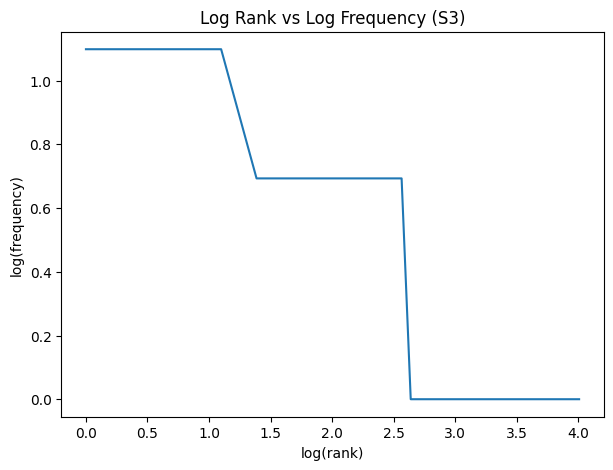

Top 5 Bigrams of S1
[(('.', 'the'), 3), (('yesterday', '.'), 3), (('.', 'can'), 3), (('can', 'you'), 3), (('you', 'check'), 3)]

Top 5 Bigrams of S3
[(('wifi', 'restarting'), 2), (('restarting', 'system'), 2), (('system', 'problem'), 2), (('problem', 'occurs'), 2), (('check', 'server'), 2)]


In [26]:
#Q5

from nltk.stem import PorterStemmer
from nltk.probability import FreqDist
from nltk.util import bigrams
import matplotlib.pyplot as plt
import math


S1 = []
S2 = []
S3 = []

for _, row in df.iterrows():

    result = process_ticket(row["Ticket_Text"])

    S1.extend(result["tokens"])

    # removing punctuation only
    S2.extend([t for t in result["tokens"] if not is_punct(t)])

    # final tokens
    S3.extend(result["final"])


# Porter stemming on S3
porter = PorterStemmer()

S4 = [porter.stem(word) for word in S3]

def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total

    return total, unique, ttr


stats = pd.DataFrame([
    ["S1", *corpus_stats(S1)],
    ["S2", *corpus_stats(S2)],
    ["S3", *corpus_stats(S3)],
    ["S4", *corpus_stats(S4)]
],
columns=["Corpus", "Total Tokens", "Unique Tokens", "TTR"])


display(stats)

#Top 10 words of S1 and S3

print("Top 10 words in S1")

fdist_S1 = FreqDist(S1)
print(fdist_S1.most_common(10))


print("\nTop 10 words in S3")

fdist_S3 = FreqDist(S3)
print(fdist_S3.most_common(10))

#Plot log(rank) vs log(frequency) for S3

frequency = sorted(
    fdist_S3.values(),
    reverse=True
)

rank = range(1, len(frequency)+1)

log_rank = [math.log(r) for r in rank]
log_frequency = [math.log(f) for f in frequency]


plt.figure(figsize=(7,5))

plt.plot(log_rank, log_frequency)

plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log Rank vs Log Frequency (S3)")

plt.show()

#3. Top 5 bigrams of S1 and S3

print("Top 5 Bigrams of S1")

bigram_S1 = FreqDist(bigrams(S1))
print(bigram_S1.most_common(5))


print("\nTop 5 Bigrams of S3")

bigram_S3 = FreqDist(bigrams(S3))
print(bigram_S3.most_common(5))

In [ ]:
#Q6
#(a) Why does TTR change from S1 to S4 in your dataset?
#TTR (Type-Token Ratio) changes because preprocessing and stemming reduce the number of unique words.
#From S1 to S4, punctuation and stopwords are removed, and stemming converts different word forms into a common root. This decreases unique tokens, causing the TTR value to change.

#(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
#Text:
#I can't access Wi-Fi.
#word_tokenize():
#['I', 'ca', "n't", 'access', 'Wi-Fi', '.']
#my_tokenize():
#['I', "can't", 'access', 'Wi-Fi']
#The difference is that word_tokenize() splits contractions into separate tokens,
#while the custom regex tokenizer preserves contractions as a single token.

#(c) Give one example where stemming produces an undesirable result.
#studies → studi

#(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.
#Stemming (Porter Stemmer):
#was → wa
#POS-aware Lemmatization (WordNet Lemmatizer):
#was → be
